In [1]:
import numpy as np
import matplotlib.pyplot as plt
import os
import astropy.units as u
import json

import matplotlib.colors as mcolors
import matplotlib.lines as mlines

from transform_data import get_transformed_data
from field_config import field_lims, field_labels, field_scales

import flash_amr_tools
import h5py
from scipy.interpolate import CubicSpline
from scipy.integrate import cumulative_trapezoid

In [2]:
fig_dir = "/home/kwatanabe/Projects/cr-bowshocks/figures/1d_proj"
flash_output_dir = "/home/kwatanabe/Projects/cr-bowshocks/outputs"
data_dir = "/home/kwatanabe/Projects/cr-bowshocks/crbowshock_analysis_tools/data"

# load the bowshock config
bowshock_config = json.load(open("../config/bowshock_config.json", "r"))["config"]

sim_name = "ISM-v30"

In [3]:
sim_dir = bowshock_config[sim_name]["sim_dir"]

In [4]:
# read the data
with h5py.File(f"{data_dir}/source_stellar.h5", "r") as f:

    Nstep = f["Nstep"][()]  # number of timesteps

    times_tmp = f["20"]["times"][()][:150] * u.s
    vwinds = f["20"]["vwinds"][()][:150] * (u.cm / u.s)
    Mdots = f["20"]["Mdots"][()][:150] * (u.g / u.s)

Lwinds = (0.5 * Mdots * vwinds**2).to(u.erg/u.s)
f_lwind = CubicSpline(x=times_tmp, y=Lwinds)

In [5]:
time_data = np.genfromtxt(os.path.join(flash_output_dir, sim_dir, "CRsources.dat"), delimiter=" ", skip_header=1)
total_time = time_data[:,0] * u.s
Ecrs_tot = time_data[:,4] * u.erg
Ecrs_tot = Ecrs_tot[np.argsort(total_time)]
total_time = total_time[np.argsort(total_time)]

Ewind = cumulative_trapezoid(f_lwind(total_time), x=total_time.to_value(u.s)) * u.erg

In [6]:
total_output_data = np.genfromtxt(os.path.join(flash_output_dir, sim_dir, "starISM.dat"),  skip_header=1)
time1 = total_output_data[:,0] * u.s
E_tot = total_output_data[:,5] * u.erg
E_int = total_output_data[:,6] * u.erg

Ewind = cumulative_trapezoid(f_lwind(total_time), x=total_time.to_value(u.s)) * u.erg

Text(0.5, 1.0, 'Cumulative energy for each component')

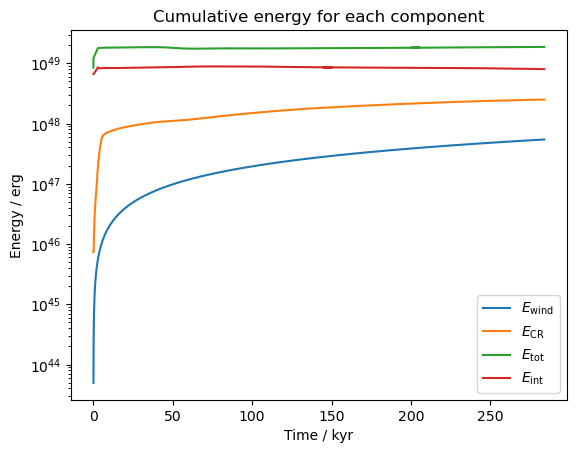

In [22]:
plt.semilogy(total_time[1:].to(u.kyr),  Ewind, label=r"$E_\mathrm{wind}$")
plt.semilogy(total_time.to(u.kyr),  Ecrs_tot, label=r"$E_\mathrm{CR}$")
plt.semilogy(time1.to(u.kyr),  E_tot, label=r"$E_\mathrm{tot}$")
plt.semilogy(time1.to(u.kyr),  E_int, label=r"$E_\mathrm{int}$")
# plt.semilogy(times,  )

plt.legend()
plt.xlabel("Time / kyr")
plt.ylabel("Energy / erg")
plt.title("Cumulative energy for each component")

Text(0, 0.5, '$E$ / $E_\\mathrm{tot}$')

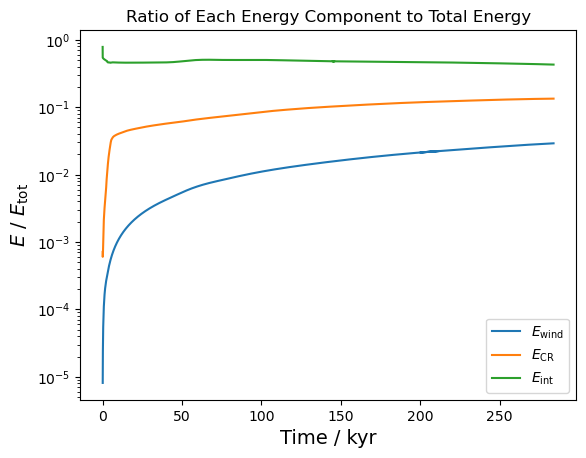

In [23]:
Ewind_1 = cumulative_trapezoid(f_lwind(time1), x=time1.to_value(u.s)) * u.erg
E_tot_2 = np.interp(x=total_time.to(u.kyr), xp=np.sort(time1).to(u.kyr), fp=E_tot[np.argsort(time1)])
plt.semilogy(time1[1:].to(u.kyr),  Ewind_1 / E_tot[1:], label=r"$E_\mathrm{wind}$")
plt.semilogy(total_time.to(u.kyr),  Ecrs_tot / E_tot_2, label=r"$E_\mathrm{CR}$")
plt.semilogy(time1.to(u.kyr),  E_int / E_tot, label=r"$E_\mathrm{int}$")

plt.legend()
plt.title("Ratio of Each Energy Component to Total Energy")
plt.xlabel("Time / kyr", fontsize=14)
plt.ylabel("$E$ / $E_\mathrm{tot}$", fontsize=14)

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


Text(0, 0.5, 'Ratio of Ecr to Eint')

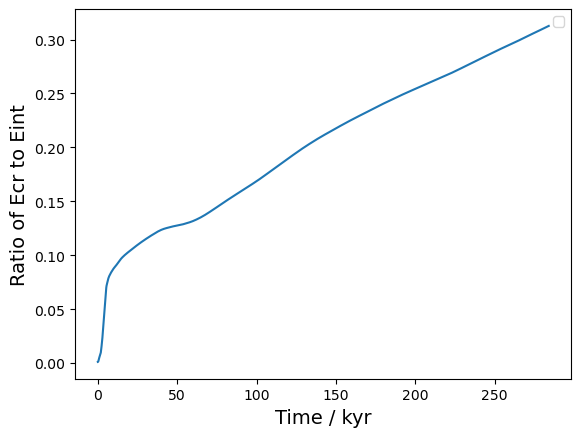

In [26]:
E_int_2 = np.interp(x=total_time.to(u.kyr), xp=np.sort(time1).to(u.kyr), fp=E_int[np.argsort(time1)])
plt.plot(total_time.to(u.kyr),  Ecrs_tot / E_int_2)

plt.legend()
# plt.title("Ratio of Each Energy Component to Total Energy")
plt.xlabel("Time / kyr", fontsize=14)
plt.ylabel("Ratio of Ecr to Eint", fontsize=14)